# Story 4 — Is Food Safety Improving Over Time?

**Research question:** What do recorded 311 sanitation complaints and graded food-inspection outcomes reveal about changing conditions in Chicago, 2011–2025?

**Scope:** Counts measure reporting/service activity; inspection failure shares measure observed outcomes **among graded inspections**, not citywide underlying prevalence. **2010 and 2026 are excluded** because archive coverage is partial. Neither trend alone proves that food safety improved or worsened.

## Setup and embedded verified aggregates

All figures below are computed from **aggregated results derived from the five user-provided Chicago ZIP archives**, with duplicate request IDs and inspection IDs removed. Figures are embedded in this executed notebook and can be recalculated **without uploading raw ZIPs**. All estimates refer to **2011–2025 complete comparison years**, unless explicitly noted. See the README for methodology. ZIP codes are only proxies for neighborhoods; same ZIP/address is not proof a 311 complaint relates to a specific food establishment.

In [1]:
import json
import builtins
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize':(9.3,4.6),'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'axes.titleweight':'bold','font.size':10})
BLUE='#28679c'; TEAL='#18877b'; ORANGE='#e19531'; RED='#c95756'; GREY='#7c8791'
def pct(x, n): return 100*x/n if n else np.nan
def style(ax, title, ylabel=None, xlabel=None):
    ax.set_title(title,loc='left',pad=14,fontsize=12)
    if ylabel: ax.set_ylabel(ylabel)
    if xlabel: ax.set_xlabel(xlabel)
    ax.grid(axis='y',alpha=.18)
    ax.set_axisbelow(True)
    plt.tight_layout()
def show():
    plt.show()

annual = pd.DataFrame(json.loads(r'''[{"year":2011,"complaints":17922,"inspections":18706,"graded":17547,"fails":4346,"conditional":1516,"fail_pct":24.76776656978401,"conditional_pct":8.639653502023139},{"year":2012,"complaints":19122,"inspections":18815,"graded":15979,"fails":3635,"conditional":1530,"fail_pct":22.74860754740597,"conditional_pct":9.575067275799487},{"year":2013,"complaints":17939,"inspections":20918,"graded":17050,"fails":3343,"conditional":1755,"fail_pct":19.607038123167154,"conditional_pct":10.29325513196481},{"year":2014,"complaints":18842,"inspections":21516,"graded":18600,"fails":3711,"conditional":2308,"fail_pct":19.951612903225808,"conditional_pct":12.408602150537634},{"year":2015,"complaints":19274,"inspections":20894,"graded":17877,"fails":3605,"conditional":2155,"fail_pct":20.165575879621862,"conditional_pct":12.054595290037478},{"year":2016,"complaints":20927,"inspections":22795,"graded":19843,"fails":4294,"conditional":2633,"fail_pct":21.639873003074133,"conditional_pct":13.269162928992591},{"year":2017,"complaints":19703,"inspections":21534,"graded":18455,"fails":4110,"conditional":2131,"fail_pct":22.27038742888106,"conditional_pct":11.547006231373611},{"year":2018,"complaints":17944,"inspections":17158,"graded":14824,"fails":3315,"conditional":5154,"fail_pct":22.362385321100916,"conditional_pct":34.76794387479762},{"year":2019,"complaints":12260,"inspections":19027,"graded":16099,"fails":3608,"conditional":7927,"fail_pct":22.41132989626685,"conditional_pct":49.23908317286788},{"year":2020,"complaints":14965,"inspections":15095,"graded":12578,"fails":2926,"conditional":3927,"fail_pct":23.26283987915408,"conditional_pct":31.221179837812052},{"year":2021,"complaints":18453,"inspections":15833,"graded":13109,"fails":3027,"conditional":3181,"fail_pct":23.09100617896102,"conditional_pct":24.2657716072927},{"year":2022,"complaints":14066,"inspections":16912,"graded":14263,"fails":3547,"conditional":2499,"fail_pct":24.868540980158453,"conditional_pct":17.520858164481524},{"year":2023,"complaints":13111,"inspections":18232,"graded":15391,"fails":3831,"conditional":2351,"fail_pct":24.89117016438178,"conditional_pct":15.27516080826457},{"year":2024,"complaints":13602,"inspections":19184,"graded":15957,"fails":3478,"conditional":2602,"fail_pct":21.79607695682146,"conditional_pct":16.30632324371749},{"year":2025,"complaints":14492,"inspections":19161,"graded":16024,"fails":3384,"conditional":2275,"fail_pct":21.11832251622566,"conditional_pct":14.197453819271093}]'''))
outcomes = pd.DataFrame(json.loads(r'''[{"year":2011,"graded":17547,"fails":4346,"conditional":1516,"pass":11685},{"year":2012,"graded":15979,"fails":3635,"conditional":1530,"pass":10814},{"year":2013,"graded":17050,"fails":3343,"conditional":1755,"pass":11952},{"year":2014,"graded":18600,"fails":3711,"conditional":2308,"pass":12581},{"year":2015,"graded":17877,"fails":3605,"conditional":2155,"pass":12117},{"year":2016,"graded":19843,"fails":4294,"conditional":2633,"pass":12916},{"year":2017,"graded":18455,"fails":4110,"conditional":2131,"pass":12214},{"year":2018,"graded":14824,"fails":3315,"conditional":5154,"pass":6355},{"year":2019,"graded":16099,"fails":3608,"conditional":7927,"pass":4564},{"year":2020,"graded":12578,"fails":2926,"conditional":3927,"pass":5725},{"year":2021,"graded":13109,"fails":3027,"conditional":3181,"pass":6901},{"year":2022,"graded":14263,"fails":3547,"conditional":2499,"pass":8217},{"year":2023,"graded":15391,"fails":3831,"conditional":2351,"pass":9209},{"year":2024,"graded":15957,"fails":3478,"conditional":2602,"pass":9877},{"year":2025,"graded":16024,"fails":3384,"conditional":2275,"pass":10365}]'''))


### Chart 1 | Annual sanitation requests

**Question:** Have reported sanitation problems become more or less frequent?

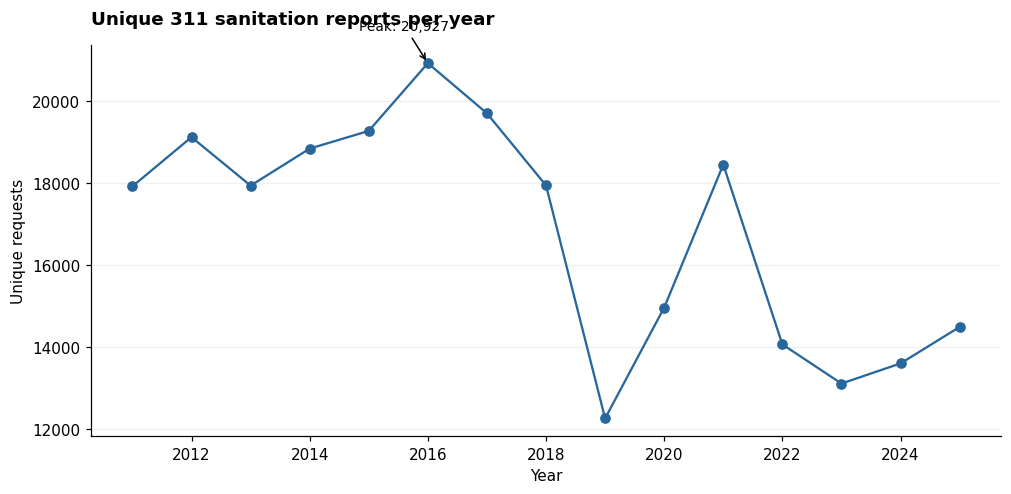

In [2]:
fig,ax=plt.subplots();ax.plot(annual.year,annual.complaints,marker='o',color=BLUE)
peak=annual.loc[annual.complaints.idxmax()];ax.annotate(f"Peak: {int(peak.complaints):,}",(peak.year,peak.complaints),xytext=(-45,22),textcoords='offset points',arrowprops={'arrowstyle':'->'},fontsize=9)
style(ax,'Unique 311 sanitation reports per year','Unique requests','Year');show()

**Interpretation:** The 2016 peak reflects recorded reporting volume. Changes can arise from true conditions, awareness, service channels, and data collection practices.

### Chart 2 | Annual graded inspection failure share

**Question:** Are food-inspection failure percentages improving or worsening?

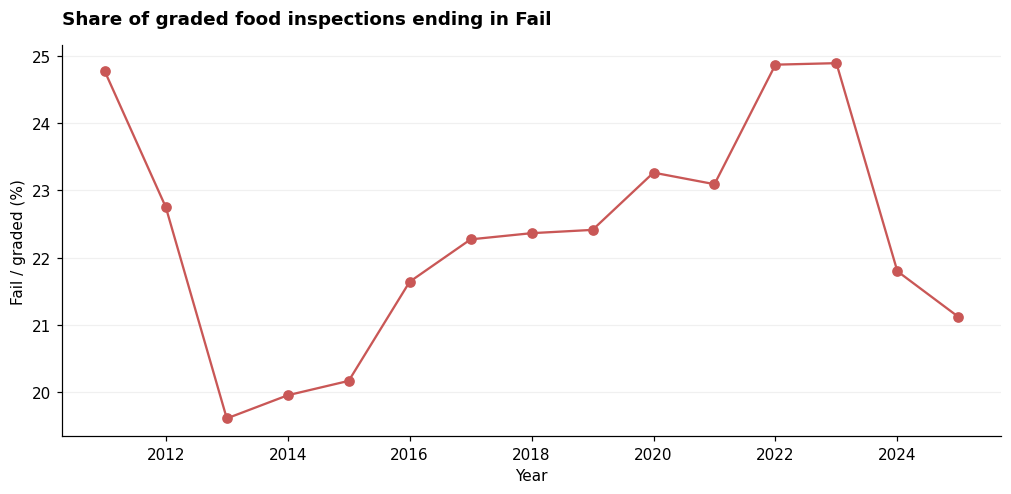

In [3]:
fig,ax=plt.subplots();ax.plot(annual.year,annual.fail_pct,marker='o',color=RED)
style(ax,'Share of graded food inspections ending in Fail','Fail / graded (%)','Year');show()

**Interpretation:** This denominator adjusts for the number of graded inspections, but not for differences in inspected business mix or enforcement criteria.

### Chart 3 | Inspection volume versus graded volume

**Question:** Did inspection activity change, affecting the number of potential failures?

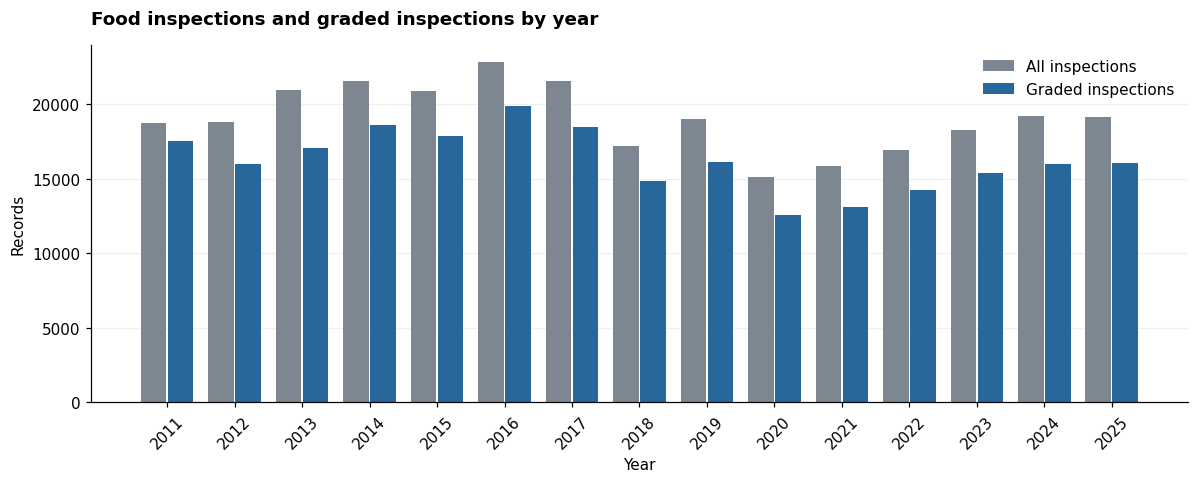

In [4]:
fig,ax=plt.subplots(figsize=(11,4.5));idx=np.arange(len(annual));ax.bar(idx-.2,annual.inspections,width=.38,color=GREY,label='All inspections');ax.bar(idx+.2,annual.graded,width=.38,color=BLUE,label='Graded inspections');ax.set_xticks(idx,annual.year.astype(int),rotation=45);ax.legend(frameon=False);style(ax,'Food inspections and graded inspections by year','Records','Year');show()

**Interpretation:** 2019 and 2020 offer a useful period for examining disruptions in inspection activity. Lower inspection volume is not proof of better or worse safety.

### Chart 4 | Outcome composition over time

**Question:** Are Fail, Pass w/ Conditions, and Pass shares changing independently?

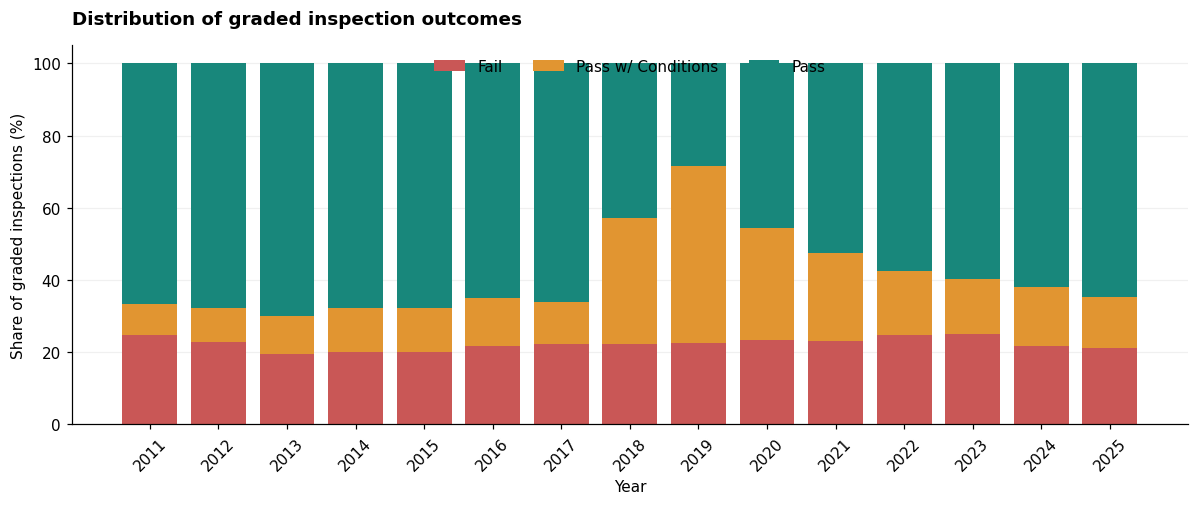

In [5]:
d=outcomes.sort_values('year');fig,ax=plt.subplots(figsize=(11,4.7));idx=np.arange(len(d));fail=100*d.fails/d.graded;condition=100*d.conditional/d.graded;pas=100*d['pass']/d.graded
ax.bar(idx,fail,color=RED,label='Fail');ax.bar(idx,condition,bottom=fail,color=ORANGE,label='Pass w/ Conditions');ax.bar(idx,pas,bottom=fail+condition,color=TEAL,label='Pass');ax.set_xticks(idx,d.year.astype(int),rotation=45);ax.legend(frameon=False,ncol=3,loc='upper center');style(ax,'Distribution of graded inspection outcomes','Share of graded inspections (%)','Year');show()

**Interpretation:** The large 2018–2019 conditional-pass share change deserves investigation into policy or coding changes; do not assume a safety trend without checking definitions.

### Chart 5 | Indexed comparison from 2011

**Question:** How do the *relative changes* in complaint volume and fail share compare?

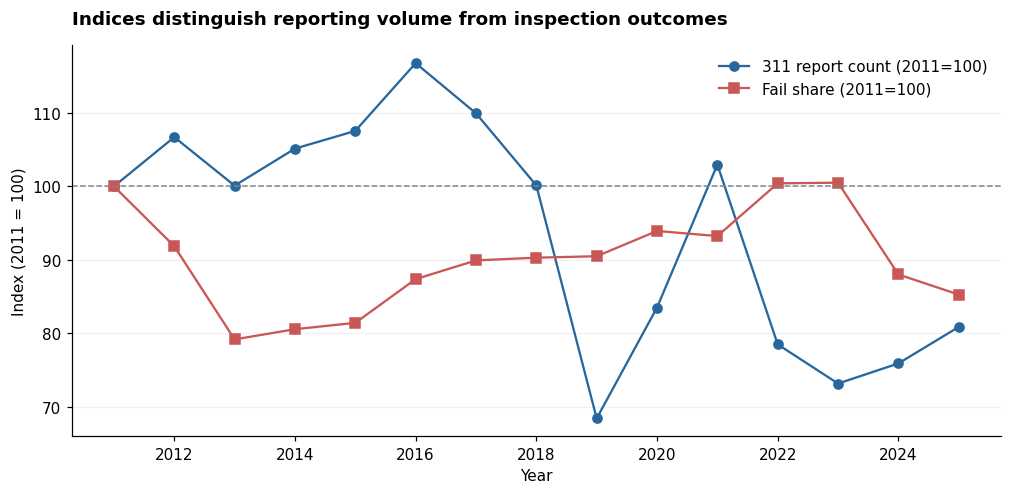

In [6]:
d=annual.sort_values('year');base=d.iloc[0];fig,ax=plt.subplots();ax.plot(d.year,100*d.complaints/base.complaints,marker='o',color=BLUE,label='311 report count (2011=100)');ax.plot(d.year,100*d.fail_pct/base.fail_pct,marker='s',color=RED,label='Fail share (2011=100)');ax.axhline(100,color=GREY,ls='--',lw=1);ax.legend(frameon=False);style(ax,'Indices distinguish reporting volume from inspection outcomes','Index (2011 = 100)','Year');show()

**Interpretation:** Indexing makes the series visually comparable but does not make them the same outcome. A rise in reports is not necessarily a rise in risk, and lower failure share may reflect inspections of different facilities.

### Chart 6 | Relationship across years

**Question:** Do years with more reported sanitation complaints also have higher food-inspection fail shares?

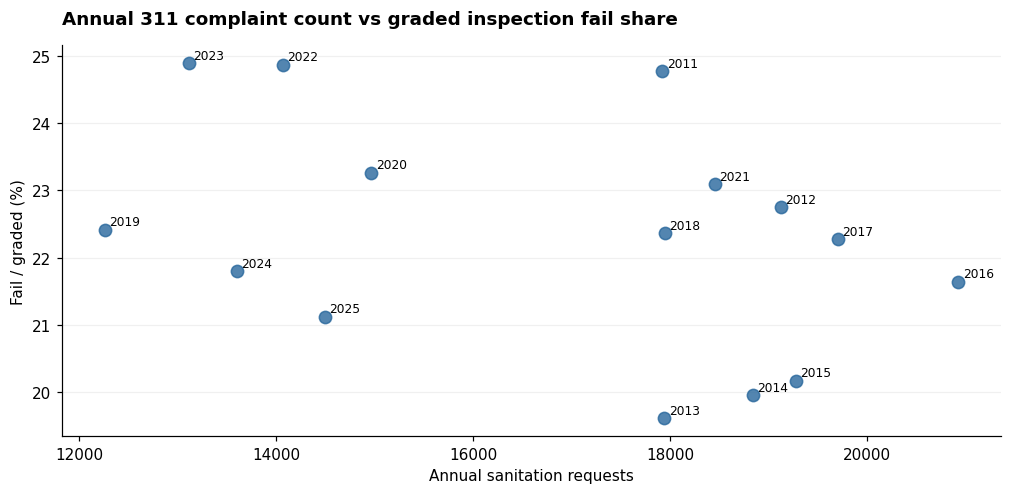

Pearson correlation across 15 years: -0.382


In [7]:
fig,ax=plt.subplots();ax.scatter(annual.complaints,annual.fail_pct,s=65,color=BLUE,alpha=.8)
for r in annual.itertuples():ax.annotate(str(int(r.year)),(r.complaints,r.fail_pct),xytext=(3,3),textcoords='offset points',fontsize=8)
style(ax,'Annual 311 complaint count vs graded inspection fail share','Fail / graded (%)','Annual sanitation requests');show()
print(f"Pearson correlation across {len(annual)} years: {annual.complaints.corr(annual.fail_pct):.3f}")

**Interpretation:** Fifteen aggregated years are too few to explain causality, and both series could be shaped by citywide reporting or enforcement changes. Do not infer improvement from one metric in isolation.

## Discussion and responsible claims

**Best answer:** Complaint totals, failure percentages, conditional passes, and inspection volume do not move in perfect lockstep. Discuss plausible explanations and measurement changes, but do not label Chicago food safety “improving” or “worsening” without further controls and external context.

## Key Findings and Business Implications

### Executive takeaway
**Recorded sanitation complaints and inspection outcomes do not tell one consistent “food safety is improving” story.** Reporting volume, inspection coverage, failure share, and conditional-pass share must be considered separately.

### Four evidence-backed findings

1. **Recorded complaints declined from the observed peak (Chart 1).** There were **20,927** unique sanitation requests in **2016**, the highest complete year in the dataset, versus **14,492** in **2025**—a **30.7%** decline in records. This is *not* equivalent to a measured reduction in hazards.
2. **The food-inspection failure share fluctuated rather than falling steadily (Chart 2).** Of graded inspections, **19.6%** failed in **2013**, **24.9%** in **2023**, and **21.1%** in **2025**. Inspection selection and rules can change which facilities enter the denominator.
3. **Inspection activity changed substantially (Chart 3).** Total inspection records decreased from **19,027** in **2019** to **15,095** in **2020**, a **20.7%** decline. The data establishes the drop, not its specific cause.
4. **Conditional passes changed sharply (Chart 4).** Pass-with-conditions outcomes were **11.5%** of graded inspections in **2017**, peaked at **49.2%** in **2019**, and were **14.2%** in **2025**. A change this large warrants investigation of definitions, enforcement, facility mix, and administrative practices before attributing it to food safety.

### Business / public-service implications

- **CDPH management:** maintain separate dashboards for inspection volume, graded outcomes, and inspection-type mix, rather than interpreting fewer failures or complaints as evidence of safer restaurants.
- **311 / public outreach:** track both complaint volume and reporting/channel changes so a decline in reported complaints is not automatically labeled a service success.
- **Inspection teams and establishments:** focus year-over-year comparisons on similar facility and inspection categories, with explicit attention to conditional-pass definitions.

### Recommended next steps

1. Investigate inspection categorization and outcome-policy changes around **2018–2020**; document any changes before interpreting the spike in conditional passes.
2. Stratify trends by inspection type, facility type, risk level, and ZIP and recompute annual failure shares in stable cohorts.
3. Add reporting denominators and uncertainty estimates, and compare all five data streams over matched complete years only.

### Limits and responsible conclusion

**2010 and 2026 are incomplete coverage years** and are omitted from these longitudinal comparisons. An administrative trend can arise from shifts in who reports, who is inspected, and how outcomes are coded. These charts justify **closer evaluation**; they cannot establish a citywide improvement or deterioration in underlying food safety.

**Source of values:** `aggregated_results/annual_comparison.csv`, whose values are also embedded in this executed notebook.
